<a href="https://colab.research.google.com/github/berinbalci/BGT208-Yapay-Zeka-Siber-Guvenlik/blob/main/Hafta-06/BGT208_Hafta06_De%C4%9Ferlendirme-Metrikleri.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BGT208 – Yapay Zekâ ve Siber Güvenlik
## Hafta 5 – Sınıflandırma Modelleri

**Amaç:** Aynı oltalama (phishing) veri seti üzerinde iki farklı sınıflandırma modeli oluşturmak, eğitmek ve tahminlerini görmek.

Bu hafta adım adım ilerleyeceğiz:
1. Kütüphaneleri tanıma
2. Veriyi Google Drive'dan yükleme
3. Özellikleri (X) ve hedefi (y) belirleme
4. Eğitim/test ayrımı
5. Logistic Regression modeli
6. Decision Tree modeli
7. Tahminleri yan yana inceleme

**Sınıflar:** `0 = Phishing (oltalama)`, `1 = Legitimate (güvenilir)`.

> Bu hafta performans metrikleri hesaplamıyoruz. Accuracy, Precision, Recall, F1 ve Confusion Matrix 6. haftanın konusu.

## 1. Adım – Kütüphaneleri içe aktarma

**Pandas:** CSV dosyasını tablo olarak okumamızı sağlar.

**train_test_split:** Veriyi eğitim ve test olarak ayırır.

**LogisticRegression:** İki sınıftan birini tahmin etmek için kullanılan sınıflandırma algoritmasıdır. Adında *regression* geçse de burada sınıflandırma yapar.

**DecisionTreeClassifier:** Sorulara ve koşullara dayalı kararlar oluşturan sınıflandırma algoritmasıdır.

**Pipeline, SimpleImputer, StandardScaler:** Eksik sayısal değerleri doldurmak ve gerektiğinde özellikleri benzer ölçeğe getirmek için kullanılır.

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

## 2. Adım – Google Drive bağlantısı

Önceki haftalarda kullandığımız CSV dosyası Google Drive'daki `BGT208` klasöründe. Bu komut Drive'a erişim izni ister.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Adım – Veri setini yükleme

`pd.read_csv()` CSV dosyasını okur. `head()` ilk beş satırı gösterir; `shape` satır ve sütun sayısını verir.

In [3]:
dosya_yolu = "/content/drive/MyDrive/bg208-yz-bilgi/PhiUSIIL_Phishing_URL_Dataset 3.csv"
df = pd.read_csv(dosya_yolu)
print("Veri boyutu (satır, sütun):", df.shape)
df.head()

Veri boyutu (satır, sütun): (235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


## 4. Adım – X ve y'yi hazırlama

- **X (özellikler):** Modelin tahmin için kullanacağı sayısal bilgiler.
- **y (hedef):** Modelin tahmin etmeye çalıştığı `label` sütunu.

`URL` gibi metin sütunlarını bu temel uygulamada kullanmıyoruz. Metinleri sayıya dönüştürme (encoding) ayrı bir hazırlık gerektirir.

`FILENAME` varsa kayıt tanımlayıcısı olduğu için çıkarıyoruz. `label` sütununu X'e koymuyoruz; aksi hâlde model cevabı önceden görmüş olur.

**Not:** Buradaki otomatik sayısal sütun seçimi öğretim amaçlıdır; gerçek projede özelliklerin anlamı ve veri sızıntısı riski ayrıca incelenmelidir.

In [4]:
X = df.select_dtypes(include="number").drop(columns=["label", "FILENAME"], errors="ignore")
y = df["label"]

print("Özellik sayısı:", X.shape[1])
print("X boyutu:", X.shape)
print("y boyutu:", y.shape)
print("Sınıflar:")
print(y.value_counts())
X.head()

NameError: name 'df' is not defined

## 5. Adım – Eğitim ve test verisini ayırma

- **Eğitim (%80):** Modelin örüntüleri öğrenmesi için.
- **Test (%20):** Modelin eğitimde görmediği örneklerde tahmin yapması için.

`random_state=42` aynı ayrımın tekrar elde edilmesini sağlar. `stratify=y` iki sınıfın oranlarını eğitim ve testte yaklaşık korur.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Eğitim:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Eğitim: (188636, 50) (188636,)
Test: (47159, 50) (47159,)


## 6. Adım – Logistic Regression modelini oluşturma

Bu model özellikleri birlikte değerlendirerek örneğin `0` mı yoksa `1` mi olduğunu tahmin etmeye çalışır.

**Ön hazırlık neden var?** Bazı sayısal sütunlar eksik değer içerebilir veya farklı büyüklüklerde olabilir. `SimpleImputer` eksikleri **yalnızca eğitim verisinden öğrendiği medyanlarla** doldurur; `StandardScaler` sayısal değerleri ölçeklendirir. `Pipeline` bu işlemleri modelle birlikte sıralar ve test verisinden bilgi sızmasını önler.

`fit()` eğitir, `predict()` tahmin üretir.

In [6]:
lojistik_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
lojistik_model.fit(X_train, y_train)
lojistik_tahmin = lojistik_model.predict(X_test)
print("Logistic Regression ilk 10 tahmin:", lojistik_tahmin[:10])

Logistic Regression ilk 10 tahmin: [1 1 1 1 1 0 1 1 1 0]


## 7. Adım – Decision Tree (Karar Ağacı) modelini oluşturma

Karar Ağacı, özellikler için koşullar oluşturarak sınıfa karar verir. Örneğin bir özelliğin belirli bir değerden büyük olup olmadığını kontrol eden dallanmalar oluşturabilir.

`max_depth=5` ağacın derinliğini sınırlar. Karar ağacında bu örnek için ölçeklendirme zorunlu değildir; eksik değerleri yine eğitim verisinden öğrenilen medyanlarla dolduruyoruz.

In [7]:
agac_modeli = make_pipeline(
    SimpleImputer(strategy="median"),
    DecisionTreeClassifier(max_depth=5, random_state=42)
)
agac_modeli.fit(X_train, y_train)
agac_tahmin = agac_modeli.predict(X_test)
print("Decision Tree ilk 10 tahmin:", agac_tahmin[:10])

Decision Tree ilk 10 tahmin: [1 1 1 1 1 0 1 1 1 0]


## KNN (K-En Yakın Komşu)

KNN, yeni bir veriyi sınıflandırırken ona en çok benzeyen örneklere bakar.

Örneğin yeni bir web sitesinin en yakın 5 komşusundan 4'ü phishing ise model bu siteyi phishing olarak sınıflandırabilir.

- `n_neighbors=5`: En yakın 5 komşu incelenir.
- `StandardScaler()`: Özelliklerin ölçeklerini düzenler.
- `fit()`: Eğitim verilerini modele aktarır.
- `predict()`: Test verileri için sınıf tahmini yapar.


In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)

print("KNN ilk 10 tahmin:")
print(knn_pred[:10])

KNN ilk 10 tahmin:
[1 1 1 1 1 0 1 1 1 0]


## Random Forest (Rastgele Orman)

Random Forest, birden fazla karar ağacının birlikte çalışmasıyla sınıflandırma yapar.

Tek bir karar ağacı yerine çok sayıda karar ağacının tahminlerinden yararlanır.

- `n_estimators=100`: Model 100 karar ağacı kullanır.
- `random_state=42`: Sonuçların tekrarlanabilir olmasını sağlar.
- `fit()`: Modeli eğitir.
- `predict()`: Test verileri için tahmin yapar.

In [10]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest ilk 10 tahmin:")
print(rf_pred[:10])

Random Forest ilk 10 tahmin:
[1 1 1 1 1 0 1 1 1 0]


## 8. Adım – Gerçek sınıflar ve tahminler

Şimdi ilk 10 test kaydı için **gerçek etiket** ile iki modelin **tahminini** yan yana gösterelim.

- `Gerçek`: Veri setindeki doğru sınıf.
- `Logistic Regression`: İlk modelin tahmini.
- `Decision Tree`: İkinci modelin tahmini.

Tabloda aynı veya farklı tahminler görebiliriz. **İlk 10 satıra bakarak hangi modelin daha iyi olduğuna karar vermiyoruz.** Bunun için 6. haftada performans ölçütleri kullanacağız.

In [13]:
sonuclar = pd.DataFrame({
    "Gerçek": y_test.iloc[:10].to_numpy(),
    "Logistic Regression": lojistik_tahmin[:10],
    "Decision Tree": agac_tahmin[:10],
    "KNN": knn_pred[:10],
    "Random Forest": rf_pred[:10]
})

sonuclar

,Gerçek,Logistic Regression,Decision Tree,KNN,Random Forest
0,1,1,1,1,1
1,1,1,1,1,1
2,1,1,1,1,1
3,1,1,1,1,1
4,1,1,1,1,1
5,0,0,0,0,0
6,1,1,1,1,1
7,1,1,1,1,1
8,1,1,1,1,1
9,0,0,0,0,0


## 9. Adım – Haftanın özeti

Bu hafta:
1. Aynı veri setini kullandık.
2. X ve y'yi belirledik.
3. Eğitim/test ayrımı yaptık.
4. **Logistic Regression** ve **Decision Tree** modellerini eğittik.
5. `predict()` ile tahminler oluşturduk.
6. Gerçek etiketlerle tahminleri yan yana inceledik.

**Temel akış:** Veri → X/y → Eğitim/Test → Model → `fit()` → `predict()`

### Öğrenciye düşünme soruları
- Modeli neden test verisiyle eğitmedik?
- `label` sütununu neden X'ten çıkardık?
- İki model aynı örnek için farklı tahmin verebilir mi?
- Yalnızca 10 tahmine bakmak neden yeterli değildir?

**Gelecek hafta:** Model Performansı ve Bias–Variance.


# 6. Hafta – Model Performansı ve Bias–Variance

## Model Performansının Değerlendirilmesi

Önceki hafta dört farklı sınıflandırma algoritması kullandık:

1. Logistic Regression
2. Decision Tree
3. KNN
4. Random Forest

Bu modelleri phishing web sitelerini tespit etmek amacıyla eğittik.

Peki hangi model daha başarılı?

Bunu anlamak için modellerin tahminlerini gerçek sonuçlarla karşılaştırmamız gerekir.

Bu hafta dört performans ölçütünü kullanacağız:

- **Accuracy:** Modelin toplam doğru tahmin oranı.
- **Precision:** Phishing olarak tahmin edilen sitelerin ne kadarı gerçekten phishing?
- **Recall:** Gerçek phishing sitelerinin ne kadarı tespit edildi?
- **F1-score:** Precision ve Recall arasındaki dengeyi gösterir.

Ayrıca Confusion Matrix ile modellerin yaptığı hataları inceleyeceğiz.

Son olarak eğitim ve test başarılarını karşılaştırarak aşırı öğrenme (overfitting) ve yetersiz öğrenme (underfitting) kavramlarını ele alacağız.

Veri setimizde:

- 0 = Phishing
- 1 = Legitimate



## Accuracy (Doğruluk)

Accuracy, modelin tüm tahminlerinin ne kadarının doğru olduğunu gösterir.

Örneğin 100 web sitesinden 90 tanesi doğru sınıflandırılmışsa:

Accuracy = 90 / 100 = 0.90

Yani modelin doğruluk oranı %90'dır.

**Kod açıklaması:**

- `accuracy_score`: Doğruluk hesaplama fonksiyonudur.
- `y_test`: Web sitelerinin gerçek sınıflarını içerir.
- `lojistik_tahmin`: Logistic Regression modelinin tahminlerini içerir.
- `accuracy_score(y_test, lojistik_tahmin)`: Gerçek sınıflarla model tahminlerini karşılaştırır.
- `print()`: Sonucu ekranda gösterir.

Aynı işlemi dört model için ayrı ayrı gerçekleştireceğiz.

**Not:** Accuracy yüksek olsa bile model bazı phishing sitelerini kaçırıyor olabilir. Bu nedenle başka ölçütlere de bakacağız.


In [14]:
from sklearn.metrics import accuracy_score

print("Logistic Regression:", accuracy_score(y_test, lojistik_tahmin))
print("Decision Tree:", accuracy_score(y_test, agac_tahmin))
print("KNN:", accuracy_score(y_test, knn_pred))
print("Random Forest:", accuracy_score(y_test, rf_pred))

Logistic Regression: 0.9998727708390763
Decision Tree: 1.0
KNN: 0.9985580695095316
Random Forest: 1.0



## Precision (Kesinlik)

Precision, modelin phishing olarak işaretlediği sitelerin ne kadarının gerçekten phishing olduğunu gösterir.

**Örnek:**

Model 100 web sitesini phishing olarak tahmin etti.

Bu sitelerin 95 tanesi gerçekten phishing, 5 tanesi güvenilir çıktı.

Precision = 95 / 100 = 0.95

Yani Precision değeri %95'tir.

**Kod açıklaması:**

- `precision_score`: Precision değerini hesaplar.
- `y_test`: Gerçek sınıflardır.
- `lojistik_tahmin`: Modelin tahminleridir.
- `pos_label=0`: Phishing sınıfını değerlendirmek istediğimizi belirtir.
- `print()`: Hesaplanan sonucu gösterir.

**Neden `pos_label=0` kullanıyoruz?**

Çünkü bizim veri setimizde phishing sınıfı 0 ile gösteriliyor.

Precision değeri yüksek olduğunda, modelin phishing uyarılarının daha büyük bir bölümü doğrudur.


In [15]:
from sklearn.metrics import precision_score

print("Logistic Regression:", precision_score(y_test, lojistik_tahmin, pos_label=0))
print("Decision Tree:", precision_score(y_test, agac_tahmin, pos_label=0))
print("KNN:", precision_score(y_test, knn_pred, pos_label=0))
print("Random Forest:", precision_score(y_test, rf_pred, pos_label=0))

Logistic Regression: 1.0
Decision Tree: 1.0
KNN: 0.999255620068483
Random Forest: 1.0



## Recall (Duyarlılık)

Recall, gerçekte phishing olan sitelerin ne kadarının model tarafından tespit edildiğini gösterir.

**Örnek:**

Veri setinde 100 phishing sitesi bulunuyor.

Model bunların 92 tanesini doğru tespit etti, 8 tanesini kaçırdı.

Recall = 92 / 100 = 0.92

Yani Recall değeri %92'dir.

**Kod açıklaması:**

- `recall_score`: Recall değerini hesaplar.
- `y_test`: Gerçek sınıfları içerir.
- `lojistik_tahmin`: Modelin tahminlerini içerir.
- `pos_label=0`: Phishing sınıfının değerlendirilmesini sağlar.

**Siber güvenlikte neden önemlidir?**

Bir phishing sitesinin güvenilir olarak tahmin edilmesi kullanıcıyı tehlikeye atabilir.

Bu nedenle phishing tespitinde Recall önemli bir ölçüttür.

**Precision ve Recall farkı:**

Precision: Phishing dediğimiz sitelerin kaçı gerçekten phishing?

Recall: Gerçek phishing sitelerinin kaçını yakaladık?


In [16]:
from sklearn.metrics import recall_score

print("Logistic Regression:", recall_score(y_test, lojistik_tahmin, pos_label=0))
print("Decision Tree:", recall_score(y_test, agac_tahmin, pos_label=0))
print("KNN:", recall_score(y_test, knn_pred, pos_label=0))
print("Random Forest:", recall_score(y_test, rf_pred, pos_label=0))

Logistic Regression: 0.9997028084600525
Decision Tree: 1.0
KNN: 0.9973748080637971
Random Forest: 1.0



## F1-score

F1-score, Precision ve Recall değerlerini birlikte değerlendiren bir ölçüttür.

Bir model phishing sitelerini çok iyi tespit edebilir ancak aynı zamanda çok sayıda güvenilir siteyi yanlışlıkla phishing olarak işaretleyebilir.

Bu nedenle yalnızca Precision veya Recall değerine bakmak yeterli olmayabilir.

F1-score bu iki ölçütün harmonik ortalamasını hesaplar.

**Formül:**

F1 = 2 × (Precision × Recall) / (Precision + Recall)

F1-score değeri 0 ile 1 arasındadır.

1'e yaklaştıkça Precision ve Recall birlikte daha yüksek düzeydedir.

**Kod açıklaması:**

- `f1_score`: F1 değerini hesaplar.
- `y_test`: Gerçek sınıfları içerir.
- `pos_label=0`: Phishing sınıfını esas alır.
- `print()`: Sonucu ekranda gösterir.


In [17]:
from sklearn.metrics import f1_score

print("Logistic Regression:", f1_score(y_test, lojistik_tahmin, pos_label=0))
print("Decision Tree:", f1_score(y_test, agac_tahmin, pos_label=0))
print("KNN:", f1_score(y_test, knn_pred, pos_label=0))
print("Random Forest:", f1_score(y_test, rf_pred, pos_label=0))

Logistic Regression: 0.9998513821460419
Decision Tree: 1.0
KNN: 0.9983143282102132
Random Forest: 1.0



## Model Performanslarının Karşılaştırılması

Şimdi dört modelin hesapladığımız performans sonuçlarını tek bir tabloda göstereceğiz.

Böylece hangi modelin hangi ölçütte daha başarılı olduğunu karşılaştırabileceğiz.

**Kod açıklaması:**

- `pd.DataFrame()`: Satır ve sütunlardan oluşan bir tablo oluşturur.
- `"Model"`: Modellerin isimlerini içerir.
- `"Accuracy"`: Her modelin doğruluk değerini içerir.
- `"Precision"`: Her modelin kesinlik değerini içerir.
- `"Recall"`: Her modelin duyarlılık değerini içerir.
- `"F1-score"`: Her modelin F1 değerini içerir.
- `.round(4)`: Sonuçları dört ondalık basamakla gösterir.
- `display()`: Tabloyu Colab ekranında görüntüler.

Burada örnek sayılar kullanmıyoruz. Kod çalıştırıldığında kendi eğittiğimiz modellerin gerçek sonuçları hesaplanacaktır.


In [21]:
import pandas as pd

metrik_tablosu = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "KNN", "Random Forest"],

    "Accuracy": [
        accuracy_score(y_test, lojistik_tahmin),
        accuracy_score(y_test, agac_tahmin),
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, rf_pred)
    ],

    "Precision": [
        precision_score(y_test, lojistik_tahmin, pos_label=0),
        precision_score(y_test, agac_tahmin, pos_label=0),
        precision_score(y_test, knn_pred, pos_label=0),
        precision_score(y_test, rf_pred, pos_label=0)
    ],

    "Recall": [
        recall_score(y_test, lojistik_tahmin, pos_label=0),
        recall_score(y_test, agac_tahmin, pos_label=0),
        recall_score(y_test, knn_pred, pos_label=0),
        recall_score(y_test, rf_pred, pos_label=0)
    ],

    "F1-score": [
        f1_score(y_test, lojistik_tahmin, pos_label=0),
        f1_score(y_test, agac_tahmin, pos_label=0),
        f1_score(y_test, knn_pred, pos_label=0),
        f1_score(y_test, rf_pred, pos_label=0)
    ]
})

display(metrik_tablosu.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.9999,1.0000,0.9997,0.9999
1,Decision Tree,1.0000,1.0000,1.0000,1.0000
2,KNN,0.9986,0.9993,0.9974,0.9983
3,Random Forest,1.0000,1.0000,1.0000,1.0000



## Confusion Matrix (Karmaşıklık Matrisi)

Confusion Matrix, modelin hangi sınıfları doğru ve yanlış tahmin ettiğini gösterir.

Bizim veri setimizde:

- 0 = Phishing
- 1 = Legitimate

| Gerçek / Tahmin | Phishing | Legitimate |
|---|---|---|
| Phishing | Doğru tespit | Kaçırılan phishing |
| Legitimate | Yanlış alarm | Doğru tespit |

**Kod açıklaması:**

- `ConfusionMatrixDisplay`: Karmaşıklık matrisini grafik olarak gösterir.
- `from_predictions()`: Gerçek ve tahmin edilen sınıfları karşılaştırır.
- `labels=[0, 1]`: Sınıfların sırasını belirler.
- `display_labels`: Grafikte sınıf adlarını gösterir.
- `cmap="Blues"`: Mavi renk tonlarını kullanır.
- `plt.show()`: Grafiği ekrana getirir.

Dört model için ayrı ayrı matris oluşturacağız.

Matrisin köşegenindeki hücreler doğru tahminleri, diğer hücreler yanlış tahminleri gösterir.


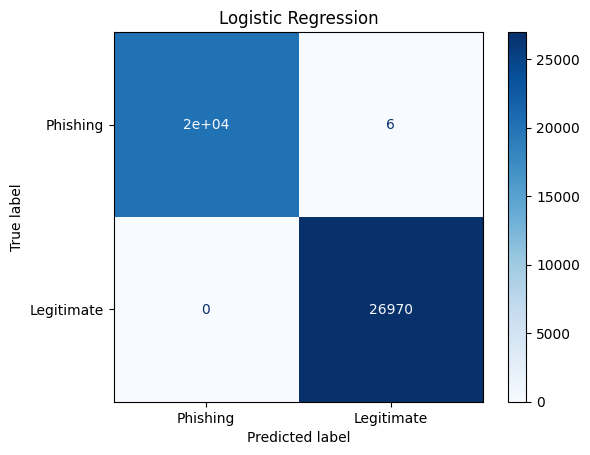

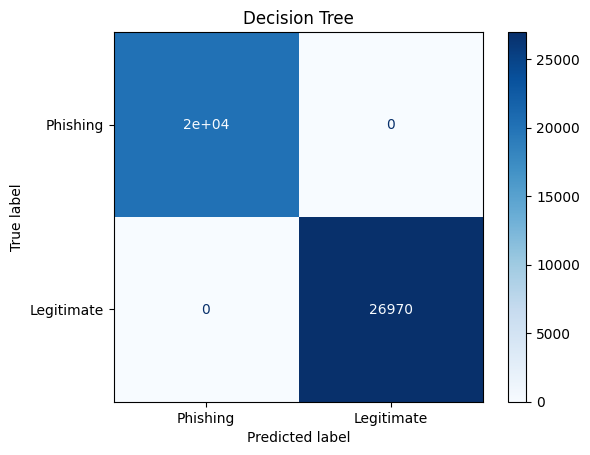

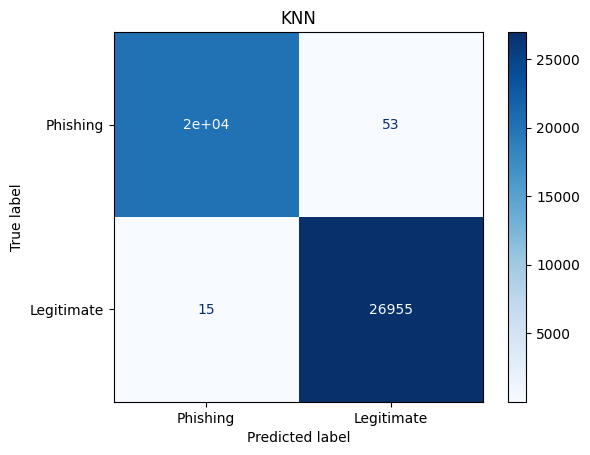

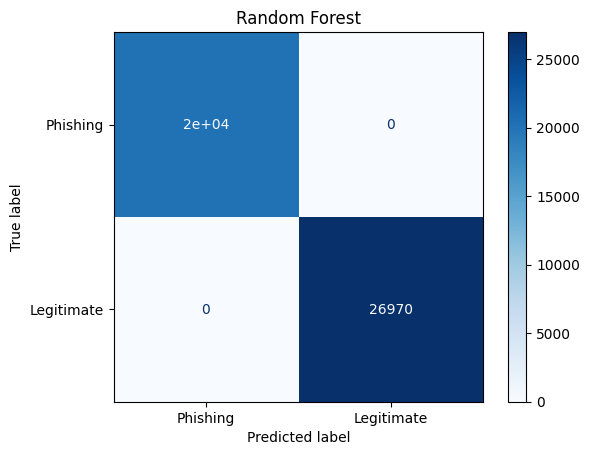

In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, lojistik_tahmin,
    labels=[0, 1],
    display_labels=["Phishing", "Legitimate"],
    cmap="Blues"
)
plt.title("Logistic Regression")
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, agac_tahmin,
    labels=[0, 1],
    display_labels=["Phishing", "Legitimate"],
    cmap="Blues"
)
plt.title("Decision Tree")
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, knn_pred,
    labels=[0, 1],
    display_labels=["Phishing", "Legitimate"],
    cmap="Blues"
)
plt.title("KNN")
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred,
    labels=[0, 1],
    display_labels=["Phishing", "Legitimate"],
    cmap="Blues"
)
plt.title("Random Forest")
plt.show()


## Model Sonuçlarının Kaydedilmesi

Colab'da eğitilen modeller ve oluşturulan değişkenler geçici bellekte tutulur.

Oturum kapandığında bunlar kaybolabilir.

Bu nedenle sonuçları Google Drive'a kaydedeceğiz.

**Kaydedilecek dosyalar:**

- `model_metrikleri.csv`: Dört modelin performans sonuçları.
- `test_tahminleri.csv`: Gerçek sınıflar ve dört modelin tahminleri.
- `egitim_test_karsilastirmasi.csv`: Eğitim ve test başarıları.
- `.joblib` dosyaları: Eğitilmiş modeller.

**Kod açıklaması:**

- `import os`: Klasör işlemlerini yapmamızı sağlar.
- `import joblib`: Eğitilmiş modelleri dosyaya kaydetmek için kullanılır.
- `os.makedirs()`: Google Drive'da klasör oluşturur.
- `exist_ok=True`: Klasör zaten varsa hata oluşmasını önler.
- `.to_csv()`: Tabloyu CSV dosyasına kaydeder.
- `index=False`: Gereksiz satır numaralarının CSV dosyasına yazılmasını önler.
- `joblib.dump()`: Eğitilmiş modeli dosyaya kaydeder.

Dosyalar `BGT208/Hafta-06` klasörüne kaydedilecektir.


In [22]:
import os
import joblib
import pandas as pd

klasor = "/content/drive/MyDrive/bg208-yz-bilgi"
os.makedirs(klasor, exist_ok=True)

# 1. Performans metriklerini kaydet
metrik_tablosu.to_csv(
    f"{klasor}/model_metrikleri.csv",
    index=False
)

# 2. Dört modelin tahminlerini kaydet
test_sonuclari = pd.DataFrame({
    "Gerçek": y_test.to_numpy(),
    "Logistic Regression": lojistik_tahmin,
    "Decision Tree": agac_tahmin,
    "KNN": knn_pred,
    "Random Forest": rf_pred
})

test_sonuclari.to_csv(
    f"{klasor}/test_tahminleri.csv",
    index=False
)

# 3. Eğitilmiş dört modeli kaydet
joblib.dump(lojistik_model, f"{klasor}/lojistik_model.joblib")
joblib.dump(agac_modeli, f"{klasor}/agac_modeli.joblib")
joblib.dump(knn_model, f"{klasor}/knn_model.joblib")
joblib.dump(rf_model, f"{klasor}/random_forest_model.joblib")

print("Tüm sonuçlar ve dört model kaydedildi.")

Tüm sonuçlar ve dört model kaydedildi.
